<a href="https://colab.research.google.com/github/chvinaysaikumar/bean_leaf_classification/blob/main/RA2311026050147_ps07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cuda


README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
Split sizes train/val/test: 1034 133 128 | total: 1295
train {'angular_leaf_spot': 345, 'bean_rust': 348, 'healthy': 341}
val {'angular_leaf_spot': 44, 'bean_rust': 45, 'healthy': 44}
test {'angular_leaf_spot': 43, 'bean_rust': 43, 'healthy': 42}


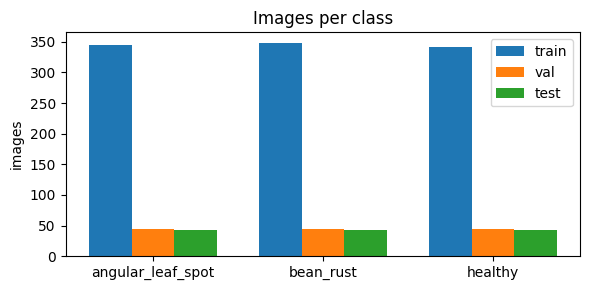

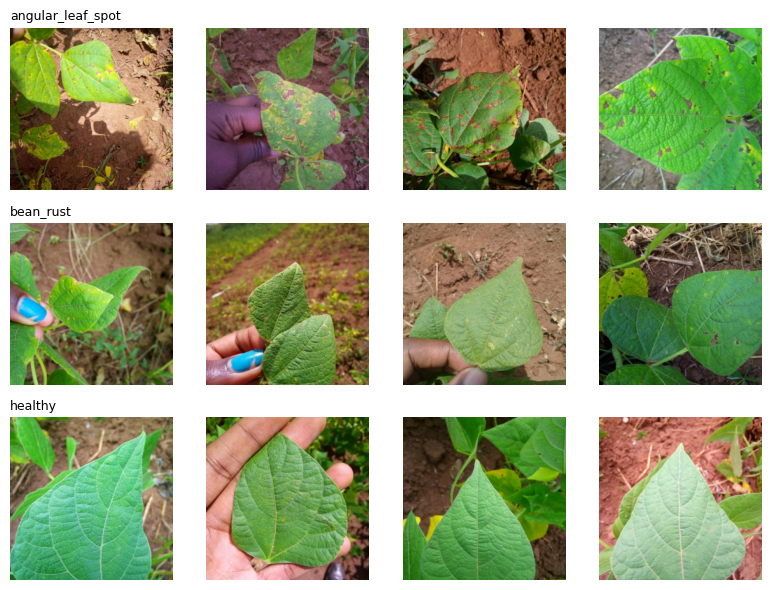

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 171MB/s]


Scratch CNN params: 241923 | EfficientNet-B0 params: 4011391

=== Model A_scratch_CNN ===
  ep  1 | train loss 0.943 acc 0.580 | val loss 0.766 acc 0.699
  ep  2 | train loss 0.848 acc 0.664 | val loss 0.675 acc 0.759
  ep  3 | train loss 0.844 acc 0.656 | val loss 0.673 acc 0.714
  ep  4 | train loss 0.799 acc 0.698 | val loss 0.686 acc 0.707
  ep  5 | train loss 0.815 acc 0.680 | val loss 0.644 acc 0.737
  ep  6 | train loss 0.785 acc 0.695 | val loss 0.679 acc 0.669
  ep  7 | train loss 0.789 acc 0.699 | val loss 0.649 acc 0.744
  ep  8 | train loss 0.777 acc 0.713 | val loss 0.638 acc 0.714
  ep  9 | train loss 0.737 acc 0.737 | val loss 0.575 acc 0.797
  ep 10 | train loss 0.751 acc 0.725 | val loss 0.651 acc 0.737
  ep 11 | train loss 0.721 acc 0.751 | val loss 0.671 acc 0.707
  ep 12 | train loss 0.719 acc 0.750 | val loss 0.638 acc 0.684
  ep 13 | train loss 0.697 acc 0.768 | val loss 0.499 acc 0.797
  ep 14 | train loss 0.671 acc 0.779 | val loss 0.496 acc 0.857
  ep 15 | trai

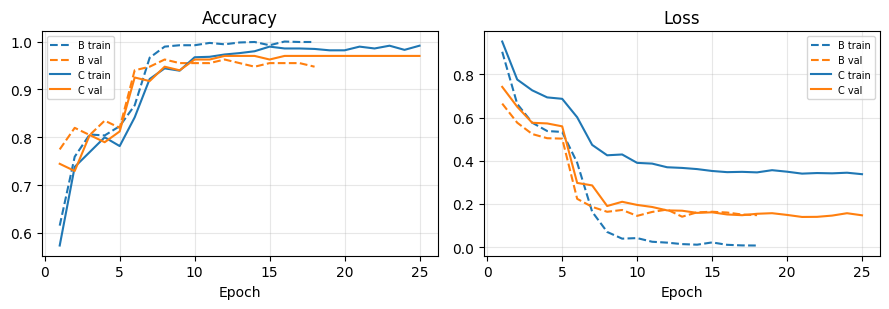

A_scratch_CNN: test acc 0.9297 | macro F1 0.9298
B_EffNetB0_no_aug: test acc 0.9531 | macro F1 0.9536
C_EffNetB0_aug_final: test acc 0.9688 | macro F1 0.9689

FINAL MODEL - per-class report (test set)
                   precision    recall  f1-score   support

angular_leaf_spot     1.0000    0.9070    0.9512        43
        bean_rust     0.9149    1.0000    0.9556        43
          healthy     1.0000    1.0000    1.0000        42

         accuracy                         0.9688       128
        macro avg     0.9716    0.9690    0.9689       128
     weighted avg     0.9714    0.9688    0.9687       128



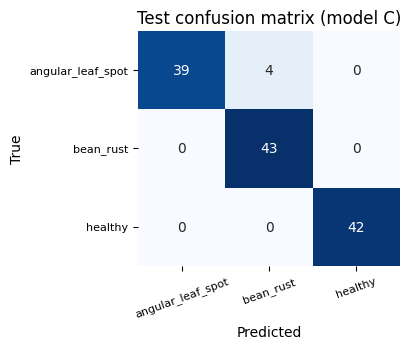

Number of misclassified test images: 4


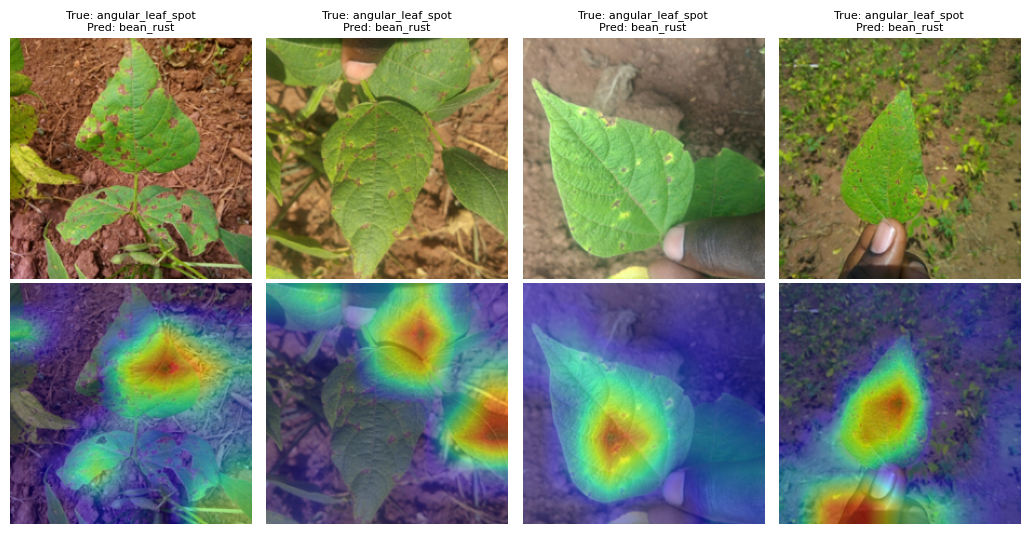

Saved results.json, fig_curves.png, fig_cm.png, fig_misclassified.png, efficientnet_b0_beans.pth


In [5]:
!pip install -q datasets

import os, random, json, time, copy
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torchvision
from torchvision import transforms, models
from PIL import Image
from datasets import load_dataset
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

SEED = 42
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)
RESULTS = {"seed": SEED, "device": str(device)}

IMG_SRC = 256
IMG = 224

hf = load_dataset("AI-Lab-Makerere/beans")
class_names = hf["train"].features["labels"].names

def load_split(split, size=IMG_SRC):
    X, y = [], []
    for ex in hf[split]:
        X.append(np.array(ex["image"].convert("RGB").resize((size, size), Image.BILINEAR)))
        y.append(int(ex["labels"]))
    return np.stack(X), np.array(y)

Xtr, ytr = load_split("train"); Xva, yva = load_split("validation"); Xte, yte = load_split("test")
NC = len(class_names)
print("Classes:", class_names)
print("Split sizes train/val/test:", len(ytr), len(yva), len(yte), "| total:", len(ytr)+len(yva)+len(yte))

counts = {n: [int((y == i).sum()) for i in range(NC)] for n, y in [("train", ytr), ("val", yva), ("test", yte)]}
for k, v in counts.items(): print(k, dict(zip(class_names, v)))
RESULTS.update({"class_names": class_names, "split_sizes": {"train": len(ytr), "val": len(yva), "test": len(yte)}, "class_counts": counts})

fig, ax = plt.subplots(figsize=(6, 3))
w = 0.25
for j, (n, v) in enumerate(counts.items()):
    ax.bar(np.arange(NC) + j*w, v, w, label=n)
ax.set_xticks(np.arange(NC) + w); ax.set_xticklabels(class_names); ax.set_ylabel("images"); ax.legend(); ax.set_title("Images per class")
plt.tight_layout(); plt.savefig("fig_class_counts.png", dpi=200); plt.show()

fig, axes = plt.subplots(NC, 4, figsize=(8, 2*NC))
for c in range(NC):
    idx = np.where(ytr == c)[0][:4]
    for k, i in enumerate(idx):
        axes[c, k].imshow(Xtr[i]); axes[c, k].axis("off")
        if k == 0: axes[c, k].set_title(class_names[c], fontsize=9, loc="left")
plt.tight_layout(); plt.savefig("fig_samples.png", dpi=150); plt.show()

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_aug = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
tf_plain = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class NpDS(torch.utils.data.Dataset):
    def __init__(self, X, y, tf): self.X, self.y, self.tf = X, y, tf
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.tf(Image.fromarray(self.X[i])), int(self.y[i])

BS = 32
def loader(X, y, tf, shuffle):
    g = torch.Generator(); g.manual_seed(SEED)
    return torch.utils.data.DataLoader(NpDS(X, y, tf), batch_size=BS, shuffle=shuffle, num_workers=2, generator=g)

train_aug = loader(Xtr, ytr, tf_aug, True)
train_plain = loader(Xtr, ytr, tf_plain, True)
val_loader = loader(Xva, yva, tf_plain, False)
test_loader = loader(Xte, yte, tf_plain, False)

def build_scratch():
    def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(blk(3, 32), blk(32, 64), blk(64, 128), blk(128, 128),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, NC))

def build_effnet():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(1280, NC)
    return m

def n_params(m): return sum(p.numel() for p in m.parameters())
print("Scratch CNN params:", n_params(build_scratch()), "| EfficientNet-B0 params:", n_params(build_effnet()))

ce = nn.CrossEntropyLoss()
ce_smooth = nn.CrossEntropyLoss(label_smoothing=0.1)

@torch.no_grad()
def evaluate(model, dl):
    model.eval(); loss = correct = n = 0; P, L = [], []
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss += ce(out, y).item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
        P += out.argmax(1).cpu().tolist(); L += y.cpu().tolist()
    return loss/n, correct/n, np.array(P), np.array(L)

def fit(model, train_dl, lr, epochs, patience, hist, criterion, wd=1e-4):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, best_state, bad = 1e9, copy.deepcopy(model.state_dict()), 0
    for ep in range(epochs):
        model.train(); tl = tc = tn = 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            out = model(x); loss = criterion(out, y); loss.backward(); opt.step()
            tl += loss.item()*len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        sched.step()
        vl, va, _, _ = evaluate(model, val_loader)
        hist["train_loss"].append(tl/tn); hist["train_acc"].append(tc/tn); hist["val_loss"].append(vl); hist["val_acc"].append(va)
        print(f"  ep {len(hist['val_loss']):2d} | train loss {tl/tn:.3f} acc {tc/tn:.3f} | val loss {vl:.3f} acc {va:.3f}")
        if vl < best - 1e-4: best, bad, best_state = vl, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience: print("  early stopping"); break
    model.load_state_dict(best_state)
    return hist

HP = {"batch_size": BS, "optimizer": "AdamW", "weight_decay": 1e-4, "scheduler": "CosineAnnealing",
      "head_lr": 1e-3, "head_epochs": 5, "finetune_lr": 1e-4, "finetune_max_epochs": 20, "patience": 5,
      "label_smoothing": 0.1, "input": IMG, "seed": SEED}
RESULTS["hyperparameters"] = HP

def new_hist(): return {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
trained, hists, times = {}, {}, {}

def run(name, builder, train_dl, criterion, two_stage):
    print("\n=== Model", name, "===")
    seed_all(SEED); m = builder().to(device); h = new_hist(); t0 = time.time()
    if two_stage:
        for p in m.features.parameters(): p.requires_grad = False
        fit(m, train_dl, HP["head_lr"], HP["head_epochs"], 99, h, criterion)
        for p in m.parameters(): p.requires_grad = True
        fit(m, train_dl, HP["finetune_lr"], HP["finetune_max_epochs"], HP["patience"], h, criterion)
    else:
        fit(m, train_dl, 1e-3, 40, HP["patience"], h, criterion)
    times[name] = time.time() - t0; trained[name] = m; hists[name] = h
    print(f"  training time {times[name]:.0f}s, epochs run {len(h['val_loss'])}")

run("A_scratch_CNN", build_scratch, train_aug, ce_smooth, two_stage=False)
run("B_EffNetB0_no_aug", build_effnet, train_plain, ce, two_stage=True)
run("C_EffNetB0_aug_final", build_effnet, train_aug, ce_smooth, two_stage=True)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for name, ls in [("B_EffNetB0_no_aug", "--"), ("C_EffNetB0_aug_final", "-")]:
    h = hists[name]; e = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(e, h["train_acc"], ls, color="C0", label=f"{name[:1]} train"); axes[0].plot(e, h["val_acc"], ls, color="C1", label=f"{name[:1]} val")
    axes[1].plot(e, h["train_loss"], ls, color="C0", label=f"{name[:1]} train"); axes[1].plot(e, h["val_loss"], ls, color="C1", label=f"{name[:1]} val")
axes[0].set_title("Accuracy"); axes[1].set_title("Loss")
for a in axes: a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("fig_curves.png", dpi=200); plt.show()

final = "C_EffNetB0_aug_final"
RESULTS["final_model"] = final; RESULTS["models"] = {}
preds = {}
for name, m in trained.items():
    tl, ta, P, L = evaluate(m, test_loader); preds[name] = (P, L)
    rep = classification_report(L, P, labels=list(range(NC)), target_names=class_names, output_dict=True, zero_division=0)
    h = hists[name]
    RESULTS["models"][name] = {
        "params": n_params(m), "test_acc": float(accuracy_score(L, P)), "macro_f1": float(f1_score(L, P, average="macro")),
        "test_loss": tl, "train_time_s": times[name], "epochs_run": len(h["val_loss"]),
        "final_train_acc": h["train_acc"][-1], "best_val_acc": max(h["val_acc"]),
        "per_class": {c: {k: float(rep[c][k]) for k in ("precision", "recall", "f1-score", "support")} for c in class_names}}
    print(f"{name}: test acc {ta:.4f} | macro F1 {RESULTS['models'][name]['macro_f1']:.4f}")

P, L = preds[final]
print("\nFINAL MODEL - per-class report (test set)")
print(classification_report(L, P, target_names=class_names, digits=4))

cm = confusion_matrix(L, P, labels=list(range(NC)))
plt.figure(figsize=(4.2, 3.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Test confusion matrix (model C)")
plt.xticks(rotation=20, fontsize=8); plt.yticks(rotation=0, fontsize=8)
plt.tight_layout(); plt.savefig("fig_cm.png", dpi=200); plt.show()
RESULTS["confusion_matrix"] = cm.tolist()

def gradcam(model, x, target):
    feats, grads = {}, {}
    layer = model.features[-1]
    h1 = layer.register_forward_hook(lambda m, i, o: feats.update(a=o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.update(g=go[0]))
    model.eval(); out = model(x); model.zero_grad(); out[0, target].backward()
    h1.remove(); h2.remove()
    w = grads["g"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * feats["a"]).sum(1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=(IMG, IMG), mode="bilinear")[0, 0]
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()

m = trained[final]
wrong = np.where(P != L)[0]
print("Number of misclassified test images:", len(wrong))
show = wrong[:6]
if len(show):
    fig, axes = plt.subplots(2, len(show), figsize=(2.6*len(show), 5.4), squeeze=False)
    for k, i in enumerate(show):
        img = Xte[i]; x = tf_plain(Image.fromarray(img)).unsqueeze(0).to(device)
        cam = gradcam(m, x, int(P[i]))
        axes[0, k].imshow(Image.fromarray(img).resize((IMG, IMG))); axes[0, k].axis("off")
        axes[0, k].set_title(f"True: {class_names[L[i]]}\nPred: {class_names[P[i]]}", fontsize=8)
        axes[1, k].imshow(Image.fromarray(img).resize((IMG, IMG))); axes[1, k].imshow(cam, cmap="jet", alpha=0.45); axes[1, k].axis("off")
    plt.tight_layout(); plt.savefig("fig_misclassified.png", dpi=150); plt.show()

torch.save({"model_state_dict": trained[final].state_dict(), "class_names": class_names, "hyperparameters": HP}, "efficientnet_b0_beans.pth")
with open("results.json", "w") as f: json.dump(RESULTS, f, indent=2)
print("Saved results.json, fig_curves.png, fig_cm.png, fig_misclassified.png, efficientnet_b0_beans.pth")

In [6]:
!zip -q ps07_outputs.zip results.json fig_*.png
from google.colab import files
files.download("ps07_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>